# What does the market pay for? A neural-network fair-value model for Indian large caps

**Advanced ML project, GIM (pilot on 20 NIFTY 50 non-financial companies)**

The project asks two questions:

1. **Can a model explain a company's valuation (price-to-book) from its fundamentals?** Here we compare a linear model, two tree ensembles and a tuned neural network.
2. **Does the gap between actual and "fair" valuation predict the next year's return?** In other words, do stocks that look cheap for their fundamentals go on to beat the ones that look expensive?

Inside the project sits a **neural network tuning study**: a seeded hyperparameter search, a seed-sensitivity test, an ablation of input groups and an interpretability check.

### How to run
**Google Colab:** keep this notebook inside the `Project2` folder on Google Drive, open it from Drive with Colab, and choose **Runtime → Run all**. When asked, allow access to Google Drive. The notebook finds the `Project2` folder by itself.

**Local Jupyter:** open this notebook from the `Project2` folder and choose **Kernel → Restart Kernel and Run All Cells**.

Then, in either case:
1. **The first run** downloads weekly prices from Yahoo Finance once and saves them to `data/raw/prices_weekly.csv`, with a checksum. Every later run reads that frozen file and does not use the internet.
2. The last cell prints a **results fingerprint**. Rerunning the notebook prints `IDENTICAL to previous run`.

The whole run takes a few minutes on a laptop CPU. No GPU or PyTorch is needed: the neural network is scikit-learn's `MLPRegressor`, which gives exactly repeatable results on CPU.

## 1. Settings and determinism

In [1]:
# These must be set BEFORE numpy is imported, so that matrix maths runs on one thread
# and gives bit-identical results on every run.
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[_v] = "1"
os.environ["PYTHONHASHSEED"] = "0"

import sys, importlib.util
from pathlib import Path

SEED = 42
PROJECT_OVERRIDE = ""   # optional: full path to the Project2 folder if it isn't found automatically

def find_project():
    """Locate the project folder: Google Drive on Colab, the notebook's own folder locally."""
    if PROJECT_OVERRIDE:
        return Path(PROJECT_OVERRIDE)
    if importlib.util.find_spec("google.colab") is not None:
        from google.colab import drive
        drive.mount("/content/drive")
        root = Path("/content/drive/MyDrive")
        hits = []
        for depth in range(0, 7):   # search up to 6 folders deep for data/raw/MANIFEST.csv
            hits += sorted(root.glob("/".join(["*"] * depth + ["data", "raw", "MANIFEST.csv"])))
            if hits:
                break
        projects = [h.parents[2] for h in hits]
        assert projects, ("Could not find a folder containing data/raw/MANIFEST.csv in your Google Drive. "
                          "Set PROJECT_OVERRIDE above to the folder's path, e.g. '/content/drive/MyDrive/Project2'.")
        with_nb = [p for p in projects if (p / "Fair_Value_NN.ipynb").exists()]
        return (with_nb or projects)[0]
    return Path.cwd()

PROJECT = find_project()
os.chdir(PROJECT)
RAW = PROJECT / "data" / "raw"
OUT = PROJECT / "outputs"
TAB, FIG = OUT / "tables", OUT / "figures"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)

# Price download window. The END date is fixed so the frozen file never changes.
PRICE_START, PRICE_END = "2016-01-01", "2026-11-14"

# Walk-forward test years (formation each 30 June). Training always uses earlier years only.
TEST_YEARS = [2022, 2023, 2024, 2025, 2026]
BACKTEST_YEARS = [2022, 2023, 2024, 2025]   # need a full 52 weeks of returns after formation

N_TRIALS_WF = 40      # MLP random-search trials inside each walk-forward step
N_TRIALS_FULL = 60    # MLP trials for the full-sample tuning study
N_TRIALS_ABL = 20     # MLP trials per ablation variant
SEEDS = list(range(10))

UNIVERSE = {  # ticker: (sector, Yahoo symbol)
    "TCS": ("IT", "TCS.NS"), "INFY": ("IT", "INFY.NS"), "HCLTECH": ("IT", "HCLTECH.NS"),
    "WIPRO": ("IT", "WIPRO.NS"),
    "HINDUNILVR": ("FMCG", "HINDUNILVR.NS"), "ITC": ("FMCG", "ITC.NS"),
    "NESTLEIND": ("FMCG", "NESTLEIND.NS"),
    "ASIANPAINT": ("Consumer", "ASIANPAINT.NS"), "TITAN": ("Consumer", "TITAN.NS"),
    "MARUTI": ("Auto", "MARUTI.NS"), "M&M": ("Auto", "M&M.NS"), "BAJAJ-AUTO": ("Auto", "BAJAJ-AUTO.NS"),
    "SUNPHARMA": ("Pharma", "SUNPHARMA.NS"), "CIPLA": ("Pharma", "CIPLA.NS"),
    "LT": ("Industrials", "LT.NS"), "ULTRACEMCO": ("Industrials", "ULTRACEMCO.NS"),
    "TATASTEEL": ("Metals", "TATASTEEL.NS"), "HINDALCO": ("Metals", "HINDALCO.NS"),
    "NTPC": ("Utilities/Telecom", "NTPC.NS"), "BHARTIARTL": ("Utilities/Telecom", "BHARTIARTL.NS"),
}
INDEX_SYMBOL = "^NSEI"
print("Project folder:", PROJECT)
print("Running on:", "Google Colab" if "google.colab" in sys.modules else "local machine")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/GIM/AMLBT_project/Project2
Running on: Google Colab


In [2]:
import hashlib, io, json, platform, random, sys, warnings
import numpy as np
import pandas as pd
import openpyxl
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy, xgboost
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import ParameterSampler, ParameterGrid
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBRegressor

from threadpoolctl import threadpool_limits
threadpool_limits(1)   # one thread for all maths libraries -> identical results on every run
warnings.filterwarnings("ignore", category=ConvergenceWarning)
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

# Chart style: thin marks, recessive axes, fixed colour order.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#6250d6",
     "grey": "#8a8984", "ink": "#0b0b0b", "ink2": "#52514e"}
MODEL_COLORS = {"Ridge": C["blue"], "RandomForest": C["orange"], "XGBoost": C["aqua"],
                "MLP": C["violet"], "Naive (last year)": C["grey"]}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c3", "axes.labelcolor": C["ink2"],
                     "xtick.color": C["ink2"], "ytick.color": C["ink2"],
                     "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
                     "axes.titleweight": "bold", "axes.titlesize": 11,
                     "svg.hashsalt": "fixed"})

def save_table(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index)

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", metadata={"Software": None})

versions = {"python": sys.version.split()[0], "platform": platform.platform(),
            "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__, "openpyxl": openpyxl.__version__}
(OUT / "environment.json").write_text(json.dumps(versions, indent=2))
versions

{'python': '3.13.18',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'numpy': '2.4.6',
 'pandas': '2.2.3',
 'scikit-learn': '1.6.1',
 'xgboost': '3.4.1',
 'scipy': '1.16.3',
 'matplotlib': '3.10.0',
 'openpyxl': '3.1.5'}

## 2. Data integrity check

Each Screener export is checked against the SHA-256 checksum recorded in `data/raw/MANIFEST.csv` when it was downloaded. If any file has changed, the notebook stops here rather than produce different numbers.

In [3]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

manifest = pd.read_csv(RAW / "MANIFEST.csv")
bad = [r.file for r in manifest.itertuples() if sha256(RAW / r.file) != r.sha256]
assert not bad, f"These raw files changed since download: {bad}"
print(f"All {len(manifest)} fundamentals files match their recorded checksums.")
manifest[["file", "accounts", "downloaded"]].T

All 20 fundamentals files match their recorded checksums.


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
file,ASIANPAINT.xlsx,BAJAJ-AUTO.xlsx,BHARTIARTL.xlsx,CIPLA.xlsx,HCLTECH.xlsx,HINDALCO.xlsx,HINDUNILVR.xlsx,INFY.xlsx,ITC.xlsx,LT.xlsx,MARUTI.xlsx,M_M.xlsx,NESTLEIND.xlsx,NTPC.xlsx,SUNPHARMA.xlsx,TATASTEEL.xlsx,TCS.xlsx,TITAN.xlsx,ULTRACEMCO.xlsx,WIPRO.xlsx
accounts,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,standalone,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated,consolidated
downloaded,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17,2026-11-17


## 3. Read the Screener exports

Every export has a `Data Sheet` tab with 10 years of P&L, balance sheet and cash flow, Screener's year-end share price and a split/bonus-adjusted share count. Labels such as *Sales* or *Total* appear in more than one section, so rows are read section by section.

In [4]:
SECTIONS = {"META", "PROFIT & LOSS", "Quarters", "BALANCE SHEET", "CASH FLOW:", "DERIVED:"}
FIELDS = {  # our name: (section, Screener label)
    "sales": ("PROFIT & LOSS", "Sales"), "other_income": ("PROFIT & LOSS", "Other Income"),
    "depreciation": ("PROFIT & LOSS", "Depreciation"), "interest": ("PROFIT & LOSS", "Interest"),
    "pbt": ("PROFIT & LOSS", "Profit before tax"), "net_profit": ("PROFIT & LOSS", "Net profit"),
    "dividend": ("PROFIT & LOSS", "Dividend Amount"),
    "equity_capital": ("BALANCE SHEET", "Equity Share Capital"), "reserves": ("BALANCE SHEET", "Reserves"),
    "borrowings": ("BALANCE SHEET", "Borrowings"), "total_assets": ("BALANCE SHEET", "Total"),
    "cfo": ("CASH FLOW:", "Cash from Operating Activity"),
    "price_screener": ("PRICE", "PRICE:"), "adj_shares_cr": ("DERIVED:", "Adjusted Equity Shares in Cr"),
}

def read_screener(path):
    ws = openpyxl.load_workbook(path, read_only=True, data_only=True)["Data Sheet"]
    rows, section = {}, None
    for r in ws.iter_rows(values_only=True):
        if not r or r[0] is None:
            continue
        label = str(r[0]).strip()
        if label in SECTIONS:
            section = label
            continue
        key = ("PRICE", label) if label == "PRICE:" else (section, label)
        rows.setdefault(key, list(r[1:11]))          # keep the first occurrence only
    dates = rows[("PROFIT & LOSS", "Report Date")]
    for sec in ("BALANCE SHEET", "CASH FLOW:"):
        assert rows[(sec, "Report Date")] == dates, f"{path.name}: {sec} dates differ from P&L"
    out = pd.DataFrame({"report_date": pd.to_datetime(dates)})
    for name, key in FIELDS.items():
        out[name] = pd.to_numeric(pd.Series(rows.get(key, [None] * 10)), errors="coerce")
    return out.dropna(subset=["report_date"])

frames = []
for t in UNIVERSE:
    f = read_screener(RAW / f"{t.replace('&', '_')}.xlsx")
    f.insert(0, "ticker", t)
    frames.append(f)
fund_raw = pd.concat(frames, ignore_index=True).sort_values(["ticker", "report_date"], ignore_index=True)
print(fund_raw.shape)
fund_raw.groupby("ticker")["report_date"].agg(["min", "max", "count"]).T

(200, 16)


ticker,ASIANPAINT,BAJAJ-AUTO,BHARTIARTL,CIPLA,HCLTECH,HINDALCO,HINDUNILVR,INFY,ITC,LT,M&M,MARUTI,NESTLEIND,NTPC,SUNPHARMA,TATASTEEL,TCS,TITAN,ULTRACEMCO,WIPRO
min,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-12-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00,2017-03-31 00:00:00
max,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00,2026-03-31 00:00:00
count,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10


### Align each financial year to a formation date

Annual results are published within about two months of the year end. Each year's fundamentals are therefore matched to the **first 30 June at least 60 days after the year end**, so the model only uses information investors already had. For a March year end that is 30 June of the same year.

Nestlé India changed its year end from December to March. Its 15-month period ending March 2024 replaces calendar 2023, and its income and cash-flow figures are scaled to 12 months.

In [5]:
def formation_year(report_date):
    avail = report_date + pd.Timedelta(days=60)
    return avail.year if avail <= pd.Timestamp(year=avail.year, month=6, day=30) else avail.year + 1

fund = fund_raw.copy()
fund["year"] = fund["report_date"].map(formation_year)
fund = (fund.sort_values(["ticker", "report_date"])
            .drop_duplicates(["ticker", "year"], keep="last")   # e.g. Nestle Mar-2024 supersedes Dec-2023
            .reset_index(drop=True))
prev_date = fund.groupby("ticker")["report_date"].shift(1)
fund["months"] = ((fund["report_date"] - prev_date).dt.days / 30.44).round().fillna(12)
FLOWS = ["sales", "other_income", "depreciation", "interest", "pbt", "net_profit", "dividend", "cfo"]
fund[FLOWS] = fund[FLOWS].mul(12 / fund["months"], axis=0)
print("Periods not equal to 12 months:")
fund.loc[fund["months"] != 12, ["ticker", "report_date", "months", "year"]]

Periods not equal to 12 months:


,ticker,report_date,months,year
126,NESTLEIND,2024-03-31,15.0,2024


## 4. Weekly prices (downloaded once, then frozen)

The first run downloads weekly prices from Yahoo Finance for the 20 stocks and the NIFTY 50, then saves them with a checksum. Later runs refuse to continue if that file has changed. To refresh prices on purpose, delete both price files and rerun.

In [6]:
PRICE_FILE, PRICE_SUM = RAW / "prices_weekly.csv", RAW / "prices_weekly.sha256"

if not PRICE_FILE.exists():
    try:
        import yfinance as yf
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "yfinance"])
        import yfinance as yf
    symbols = [s for _, s in UNIVERSE.values()] + [INDEX_SYMBOL]
    px = yf.download(symbols, start=PRICE_START, end=PRICE_END, interval="1wk",
                     auto_adjust=False, progress=False, threads=False)
    long = pd.concat([pd.DataFrame({"date": px.index, "symbol": s,
                                    "close": px["Close"][s].to_numpy(),
                                    "adj_close": px["Adj Close"][s].to_numpy()})
                      for s in symbols if s in px["Close"].columns], ignore_index=True)
    long = long.dropna(subset=["close"])
    long["date"] = pd.to_datetime(long["date"]).dt.strftime("%Y-%m-%d")
    long = long.sort_values(["symbol", "date"]).reset_index(drop=True)
    missing = sorted(set(symbols) - set(long["symbol"]))
    assert not missing, f"Download failed for {missing}. Check your internet connection and rerun."
    long.to_csv(PRICE_FILE, index=False, float_format="%.6f")
    PRICE_SUM.write_text(sha256(PRICE_FILE))
    print(f"Downloaded and froze {len(long):,} weekly rows -> {PRICE_FILE.name}")
else:
    assert PRICE_SUM.exists() and sha256(PRICE_FILE) == PRICE_SUM.read_text().strip(), \
        "prices_weekly.csv does not match its checksum - it was edited or replaced."
    print("Using frozen price file (checksum OK).")

prices = pd.read_csv(PRICE_FILE, parse_dates=["date"])
close = prices.pivot(index="date", columns="symbol", values="close").sort_index()
adj = prices.pivot(index="date", columns="symbol", values="adj_close").sort_index()
print(close.shape, close.index.min().date(), "->", close.index.max().date())

Downloaded and froze 11,927 weekly rows -> prices_weekly.csv
(568, 21) 2015-12-28 -> 2026-11-09


### Market value at each formation date

Market cap is anchored to Screener's own year-end price and its split/bonus-adjusted share count, then moved forward to 30 June using the Yahoo price change over the same weeks:

`market cap (30 June) = Screener price at year end × adjusted shares × (Yahoo close, 30 June ÷ Yahoo close, year end)`

Because only the *ratio* of Yahoo prices is used, a different split adjustment between the two sources can't distort the level. The check below compares the two sources' year-end prices directly, as a sanity check.

In [7]:
def bar_pos(symbol, date):
    """Index of the last weekly bar dated on or before `date` (the week containing it)."""
    s = close[symbol].dropna()
    i = s.index.searchsorted(pd.Timestamp(date), side="right") - 1
    return None if i < 0 else s.index[i]

rows = []
for r in fund.itertuples():
    sym = UNIVERSE[r.ticker][1]
    form_date = pd.Timestamp(year=r.year, month=6, day=30)
    d_rep, d_form = bar_pos(sym, r.report_date), bar_pos(sym, form_date)
    rows.append({"ticker": r.ticker, "year": r.year,
                 "yf_close_report": close.at[d_rep, sym] if d_rep is not None else np.nan,
                 "yf_close_form": close.at[d_form, sym] if d_form is not None else np.nan,
                 "form_bar": d_form})
px_align = pd.DataFrame(rows)
fund = fund.merge(px_align, on=["ticker", "year"], how="left")

check = (fund.assign(ratio=fund["yf_close_report"] / fund["price_screener"])
             .groupby("ticker")["ratio"].agg(["median", "min", "max"]))
print("Yahoo ÷ Screener year-end price (1.00 = same adjustment basis):")
check.T

Yahoo ÷ Screener year-end price (1.00 = same adjustment basis):


ticker,ASIANPAINT,BAJAJ-AUTO,BHARTIARTL,CIPLA,HCLTECH,HINDALCO,HINDUNILVR,INFY,ITC,LT,M&M,MARUTI,NESTLEIND,NTPC,SUNPHARMA,TATASTEEL,TCS,TITAN,ULTRACEMCO,WIPRO
median,1.000,1.000,1.000,1.000,1.000,1.000,1.045,1.000,1.027,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,0.913,0.975,0.962,0.974,0.893,0.879,0.979,0.913,1.000,0.934,0.974,0.935,0.979,0.945,0.964,0.910,0.906,0.924,0.937,0.915
max,1.011,1.024,1.007,1.062,1.045,1.072,1.060,1.040,1.064,1.031,1.025,1.026,1.014,1.059,1.067,1.063,1.039,1.037,1.024,1.039


## 5. Build the modelling table

**Target:** log(price-to-book) on 30 June.

**Fundamental inputs** (from the latest annual accounts): return on equity, operating margin, 3-year sales growth, debt-to-equity, interest cover, asset turnover, dividend payout, cash conversion, ROE stability, size and sector.

**Market inputs** (from the 52 weekly prices before formation): momentum, volatility and beta to the NIFTY.

**Forward return** (used only in the backtest, never as an input): the total return over the 52 weeks after formation.

In [8]:
g = fund.groupby("ticker")
fund["book"] = fund["equity_capital"] + fund["reserves"]
fund["roe"] = fund["net_profit"] / ((fund["book"] + g["book"].shift(1)) / 2)
fund["op_margin"] = (fund["pbt"] + fund["interest"] + fund["depreciation"] - fund["other_income"]) / fund["sales"]
fund["sales_cagr_3y"] = (fund["sales"] / g["sales"].shift(3)) ** (1 / 3) - 1
fund["debt_equity"] = fund["borrowings"] / fund["book"]
cover = (fund["pbt"] + fund["interest"]) / fund["interest"].where(fund["interest"] > 0)
fund["log_interest_cover"] = np.log1p(cover.clip(0, 100).fillna(100))
fund["asset_turnover"] = fund["sales"] / fund["total_assets"]
fund["payout"] = (fund["dividend"] / fund["net_profit"].where(fund["net_profit"] > 0)).clip(0, 1.5)
fund["cash_conversion"] = (fund["cfo"] / fund["net_profit"].where(fund["net_profit"] > 0)).clip(-1, 3)
fund["roe_volatility_3y"] = g["roe"].transform(lambda s: s.rolling(3).std())
fund["log_sales"] = np.log(fund["sales"])

fund["mcap_cr"] = fund["price_screener"] * fund["adj_shares_cr"] * fund["yf_close_form"] / fund["yf_close_report"]
fund["log_pb"] = np.log(fund["mcap_cr"] / fund["book"])
fund["log_pb_last_year"] = fund.groupby("ticker")["log_pb"].shift(1)

# Market features and forward returns from weekly adjusted prices
idx_ret = adj[INDEX_SYMBOL].pct_change()
mkt_rows = []
for r in fund.itertuples():
    sym = UNIVERSE[r.ticker][1]
    s = adj[sym].dropna()
    if pd.isna(r.form_bar) or r.form_bar not in s.index:
        mkt_rows.append({}); continue
    i = s.index.get_loc(r.form_bar)
    rec = {}
    if i >= 52:
        win = s.iloc[i - 52:i + 1]
        ret = win.pct_change().dropna()
        m = idx_ret.reindex(ret.index)
        rec["momentum_52w"] = win.iloc[-1] / win.iloc[0] - 1
        rec["volatility_52w"] = np.log1p(ret).std() * np.sqrt(52)
        rec["beta_52w"] = np.cov(ret, m, ddof=1)[0, 1] / m.var(ddof=1)
    if i + 52 < len(s):
        rec["fwd_return_52w"] = s.iloc[i + 52] / s.iloc[i] - 1
        n = adj[INDEX_SYMBOL].dropna()
        j = n.index.get_loc(r.form_bar) if r.form_bar in n.index else None
        rec["nifty_fwd_52w"] = n.iloc[j + 52] / n.iloc[j] - 1 if j is not None and j + 52 < len(n) else np.nan
    mkt_rows.append(rec)
fund = pd.concat([fund.reset_index(drop=True), pd.DataFrame(mkt_rows)], axis=1)
fund["sector"] = fund["ticker"].map(lambda t: UNIVERSE[t][0])

FUND_FEATS = ["roe", "op_margin", "sales_cagr_3y", "debt_equity", "log_interest_cover",
              "asset_turnover", "payout", "cash_conversion", "roe_volatility_3y", "log_sales"]
MKT_FEATS = ["momentum_52w", "volatility_52w", "beta_52w"]
SECTORS = sorted({s for s, _ in UNIVERSE.values()})
SECTOR_FEATS = [f"sector_{s}" for s in SECTORS]
for s in SECTORS:
    fund[f"sector_{s}"] = (fund["sector"] == s).astype(float)

FEATURE_SETS = {"Fundamentals only": FUND_FEATS + SECTOR_FEATS,
                "Market only": MKT_FEATS,
                "Fundamentals + market": FUND_FEATS + SECTOR_FEATS + MKT_FEATS}
ALL_FEATS = FEATURE_SETS["Fundamentals + market"]

data = (fund.dropna(subset=["log_pb", "sales_cagr_3y", "roe"])
            .query("year >= 2020")
            .sort_values(["year", "ticker"]).reset_index(drop=True))
save_table(data[["ticker", "year", "sector", "log_pb"] + FUND_FEATS + MKT_FEATS +
                ["fwd_return_52w", "nifty_fwd_52w"]], "modelling_table")
print(f"Modelling table: {len(data)} company-years, {data['ticker'].nunique()} companies, "
      f"years {data['year'].min()}-{data['year'].max()}")
data.groupby("year").size().rename("companies").to_frame().T

Modelling table: 139 company-years, 20 companies, years 2020-2026


year,2020,2021,2022,2023,2024,2025,2026
companies,19,20,20,20,20,20,20


In [9]:
desc = data[["log_pb"] + FUND_FEATS + MKT_FEATS].describe().T[["mean", "std", "min", "50%", "max"]]
save_table(desc.reset_index(names="variable"), "descriptive_stats")
desc

,mean,std,min,50%,max
log_pb,1.689,1.005,-6.224e-01,1.509,4.497
roe,0.228,0.211,-4.332e-01,0.184,1.085
op_margin,0.221,0.091,6.512e-02,0.218,0.552
sales_cagr_3y,0.109,0.067,-6.916e-02,0.103,0.331
debt_equity,0.582,0.731,9.040e-04,0.176,2.914
log_interest_cover,2.958,1.303,0.000e+00,3.198,4.615
asset_turnover,0.885,0.390,2.438e-01,0.798,1.974
payout,0.493,0.303,4.731e-02,0.407,1.500
cash_conversion,1.340,0.819,-1.000e+00,1.164,3.000
roe_volatility_3y,0.050,0.067,1.490e-03,0.024,0.352


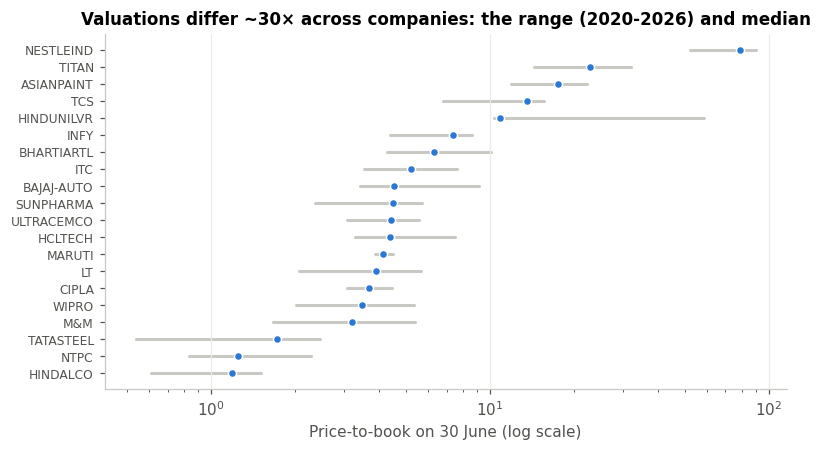

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
order = data.groupby("ticker")["log_pb"].median().sort_values().index
for k, t in enumerate(order):
    v = np.exp(data.loc[data["ticker"] == t, "log_pb"])
    ax.plot([v.min(), v.max()], [k, k], color="#c9c8c3", lw=2, solid_capstyle="round", zorder=1)
    ax.scatter(v.median(), k, s=28, color=C["blue"], zorder=2, edgecolor="white", linewidth=1)
ax.set_xscale("log"); ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set_xlabel("Price-to-book on 30 June (log scale)")
ax.set_title("Valuations differ ~30× across companies: the range (2020-2026) and median")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig1_pb_by_company"); plt.show()

## 6. Models and the tuning procedure

Every model sits in the same pipeline: median imputation → standardisation → estimator.

| Model | Role | Hyperparameters searched |
|---|---|---|
| Ridge regression | Classical linear valuation regression | L2 penalty (7 values) |
| Random Forest | Bagged tree ensemble | features per split, leaf size (4 combinations) |
| XGBoost | Boosted tree ensemble | depth, learning rate, number of trees (8 combinations) |
| **MLP (neural network)** | The model under study | architecture, activation, L2 penalty, optimiser, learning rate (seeded random search) |
| Naive benchmark | Last year's own P/B | none |

**Tuning is always done on past years only.** Within each training set, every candidate setting is scored by *leave-one-year-out* cross-validation: hold out one year, train on the rest, measure RMSE, and repeat for each year. The winning setting is then refit on all training years and used to predict the test year. Every random draw uses a fixed seed and every model runs on a single thread.

In [11]:
from scipy.stats import loguniform

MLP_SPACE = {
    "hidden_layer_sizes": [(4,), (8,), (16,), (32,), (8, 4), (16, 8), (32, 16)],
    "activation": ["relu", "tanh"],
    "alpha": loguniform(1e-3, 30),
    "solver": ["lbfgs", "adam"],
    "learning_rate_init": loguniform(1e-3, 3e-2),
}
GRIDS = {
    "Ridge": list(ParameterGrid({"alpha": [0.01, 0.1, 1, 3, 10, 30, 100]})),
    "RandomForest": list(ParameterGrid({"max_features": [0.33, 0.66], "min_samples_leaf": [2, 5]})),
    "XGBoost": list(ParameterGrid({"max_depth": [2, 3], "learning_rate": [0.03, 0.1],
                                   "n_estimators": [200, 500]})),
}

def mlp_candidates(n, seed=SEED):
    out = []
    for p in ParameterSampler(MLP_SPACE, n_iter=n, random_state=seed):
        p = dict(p)
        p["alpha"] = float(p["alpha"]); p["learning_rate_init"] = float(p["learning_rate_init"])
        out.append(p)
    return out

def build(name, params, seed=SEED):
    if name == "Ridge":
        est = Ridge(**params)
    elif name == "RandomForest":
        est = RandomForestRegressor(n_estimators=500, random_state=seed, n_jobs=1, **params)
    elif name == "XGBoost":
        est = XGBRegressor(subsample=0.8, colsample_bytree=0.8, min_child_weight=3, reg_lambda=1.0,
                           tree_method="hist", n_jobs=1, random_state=seed, verbosity=0, **params)
    elif name == "MLP":
        est = MLPRegressor(max_iter=3000 if params["solver"] == "lbfgs" else 2000,
                           random_state=seed, **params)
    else:
        raise ValueError(name)
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), est)

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def loyo_rmse(name, params, train, feats, seed=SEED):
    """Leave-one-year-out CV RMSE inside the training years."""
    errs = []
    for yr in sorted(train["year"].unique()):
        tr, va = train[train["year"] != yr], train[train["year"] == yr]
        m = build(name, params, seed).fit(tr[feats], tr["log_pb"])
        errs.append((va["log_pb"].to_numpy() - m.predict(va[feats])) ** 2)
    return float(np.sqrt(np.mean(np.concatenate(errs))))

def tune(name, train, feats, n_trials=N_TRIALS_WF, seed=SEED):
    cands = mlp_candidates(n_trials, seed) if name == "MLP" else GRIDS[name]
    log = [{**p, "cv_rmse": loyo_rmse(name, p, train, feats, seed)} for p in cands]
    log = pd.DataFrame(log)
    best = cands[int(np.argmin(log["cv_rmse"].to_numpy()))]   # first minimum -> deterministic tie-break
    return best, log

print(f"MLP search draws {N_TRIALS_WF} settings per step; first three:")
pd.DataFrame(mlp_candidates(3))

MLP search draws 40 settings per step; first three:


,activation,alpha,hidden_layer_sizes,learning_rate_init,solver
0,relu,3.683,"(32, 16)",0.012,lbfgs
1,relu,0.005,"(16,)",0.001,lbfgs
2,tanh,0.031,"(16,)",0.001,adam


## 7. Walk-forward evaluation: how well does each model explain valuations?

For each test year from 2022 to 2026, every model is tuned and trained only on earlier years, then predicts that year's P/B. The reported measures are:

- **Out-of-sample R²:** the share of the variation in log P/B the model explains, compared with simply predicting the training-years average.
- **RMSE:** the typical error in log P/B. An RMSE of 0.30 means the model is typically about 35% off in P/B terms.
- **Rank correlation:** within each year, whether the model ranks companies from cheapest to most expensive in the right order.

In [12]:
MODELS = ["Ridge", "RandomForest", "XGBoost", "MLP"]

def walk_forward(feats, models=MODELS, n_trials=N_TRIALS_WF, seed=SEED, fixed_params=None):
    preds, chosen = [], {}
    for yr in TEST_YEARS:
        train, test = data[data["year"] < yr], data[data["year"] == yr]
        out = test[["ticker", "year", "log_pb", "log_pb_last_year", "fwd_return_52w", "nifty_fwd_52w"]].copy()
        for name in models:
            if fixed_params is not None:
                params = fixed_params[(name, yr)]
            else:
                params, _ = tune(name, train, feats, n_trials, seed)
            chosen[(name, yr)] = params
            out[name] = build(name, params, seed).fit(train[feats], train["log_pb"]).predict(test[feats])
        out["train_mean"] = train["log_pb"].mean()
        preds.append(out)
    return pd.concat(preds, ignore_index=True), chosen

def score(pred, cols):
    rows = []
    for c in cols:
        d = pred.dropna(subset=[c])
        sse = ((d["log_pb"] - d[c]) ** 2).sum()
        sst = ((d["log_pb"] - d["train_mean"]) ** 2).sum()
        rank = d.groupby("year")[["log_pb", c]].apply(
            lambda x: stats.spearmanr(x["log_pb"], x[c]).statistic).mean()
        rows.append({"model": c, "oos_r2": 1 - sse / sst, "rmse": rmse(d["log_pb"], d[c]),
                     "mean_rank_corr": rank, "n": len(d)})
    return pd.DataFrame(rows)

wf_pred, wf_params = walk_forward(ALL_FEATS)
wf_pred["Naive (last year)"] = wf_pred["log_pb_last_year"]
wf_scores = score(wf_pred, MODELS + ["Naive (last year)"])
save_table(wf_scores, "table1_walkforward_scores")
save_table(wf_pred, "walkforward_predictions")
wf_scores

,model,oos_r2,rmse,mean_rank_corr,n
0,Ridge,0.827,0.402,0.887,100
1,RandomForest,0.762,0.471,0.824,100
2,XGBoost,0.785,0.447,0.865,100
3,MLP,0.866,0.353,0.906,100
4,Naive (last year),0.926,0.262,0.938,100


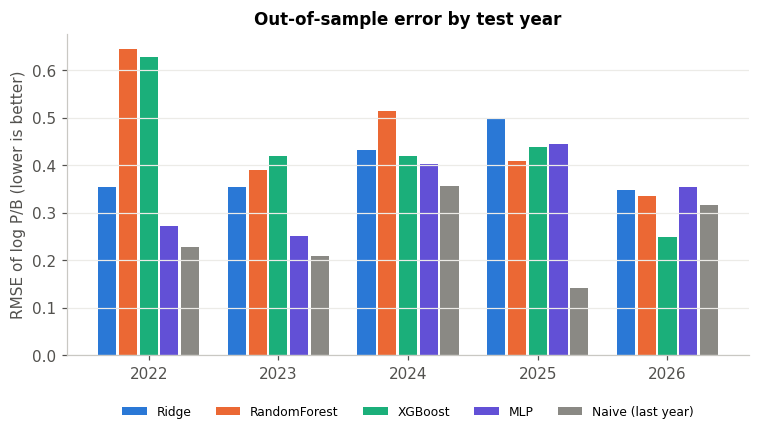

model,Ridge,RandomForest,XGBoost,MLP,Naive (last year)
year,,,,,
2022,0.353,0.644,0.628,0.271,0.228
2023,0.354,0.391,0.419,0.252,0.210
2024,0.431,0.513,0.419,0.402,0.357
2025,0.500,0.410,0.439,0.445,0.142
2026,0.348,0.336,0.249,0.355,0.316


In [13]:
by_year = []
for yr, d in wf_pred.groupby("year"):
    for c in MODELS + ["Naive (last year)"]:
        by_year.append({"year": yr, "model": c, "rmse": rmse(d["log_pb"], d[c])})
by_year = pd.DataFrame(by_year).pivot(index="year", columns="model", values="rmse")[MODELS + ["Naive (last year)"]]
save_table(by_year.reset_index(), "table2_rmse_by_year")

fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.16
for k, c in enumerate(by_year.columns):
    ax.bar(np.arange(len(by_year)) + (k - 2) * w, by_year[c], width=w - 0.02,
           color=MODEL_COLORS[c], label=c)
ax.set_xticks(range(len(by_year)), by_year.index)
ax.set_ylabel("RMSE of log P/B (lower is better)")
ax.set_title("Out-of-sample error by test year")
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)
save_fig(fig, "fig2_rmse_by_year"); plt.show()
by_year

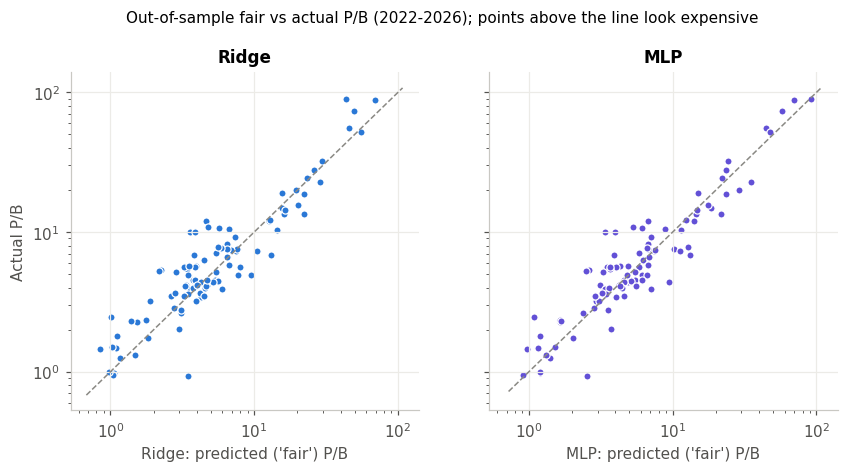

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, c in zip(axes, ["Ridge", "MLP"]):
    ax.scatter(np.exp(wf_pred[c]), np.exp(wf_pred["log_pb"]), s=22, color=MODEL_COLORS[c],
               edgecolor="white", linewidth=0.8)
    lim = [np.exp(wf_pred[["log_pb", c]].min().min()) * 0.8, np.exp(wf_pred[["log_pb", c]].max().max()) * 1.2]
    ax.plot(lim, lim, color=C["grey"], lw=1, ls="--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{c}: predicted ('fair') P/B"); ax.set_title(c)
axes[0].set_ylabel("Actual P/B")
fig.suptitle("Out-of-sample fair vs actual P/B (2022-2026); points above the line look expensive",
             fontsize=10, y=1.02)
save_fig(fig, "fig3_fair_vs_actual"); plt.show()

## 8. Neural network tuning study

### 8a. Which hyperparameters matter?

Here the full random search is run once over all seven years with leave-one-year-out CV. This search is **descriptive**: it shows how sensitive the network is to each setting. The walk-forward results above never see it.

In [15]:
best_full, search_log = tune("MLP", data, ALL_FEATS, n_trials=N_TRIALS_FULL)
search_log["architecture"] = search_log["hidden_layer_sizes"].map(lambda h: "-".join(map(str, h)))
search_log = search_log.sort_values("cv_rmse", kind="stable").reset_index(drop=True)
save_table(search_log.drop(columns="hidden_layer_sizes"), "table3_mlp_search_log")

ridge_full, ridge_log = tune("Ridge", data, ALL_FEATS)
print("Best MLP setting:", best_full)
print(f"Best MLP CV RMSE {search_log['cv_rmse'].iloc[0]:.3f}  |  "
      f"Ridge CV RMSE {ridge_log['cv_rmse'].min():.3f}  |  "
      f"Median MLP trial {search_log['cv_rmse'].median():.3f}")
search_log.drop(columns="hidden_layer_sizes").head(10)

Best MLP setting: {'activation': 'tanh', 'alpha': 1.3035002626418761, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.009437923703573482, 'solver': 'adam'}
Best MLP CV RMSE 0.306  |  Ridge CV RMSE 0.343  |  Median MLP trial 0.381


,activation,alpha,learning_rate_init,solver,cv_rmse,architecture
0,tanh,1.304,0.009,adam,0.306,32-16
1,tanh,0.686,0.016,adam,0.308,16
2,relu,0.069,0.002,lbfgs,0.309,16
3,relu,1.240,0.024,lbfgs,0.310,32-16
4,relu,3.683,0.012,lbfgs,0.311,32-16
5,tanh,0.162,0.011,adam,0.321,4
6,relu,0.516,0.003,lbfgs,0.328,8
7,relu,4.210,0.009,adam,0.330,32
8,tanh,0.001,0.024,lbfgs,0.331,16-8
9,relu,4.476,0.011,lbfgs,0.334,4


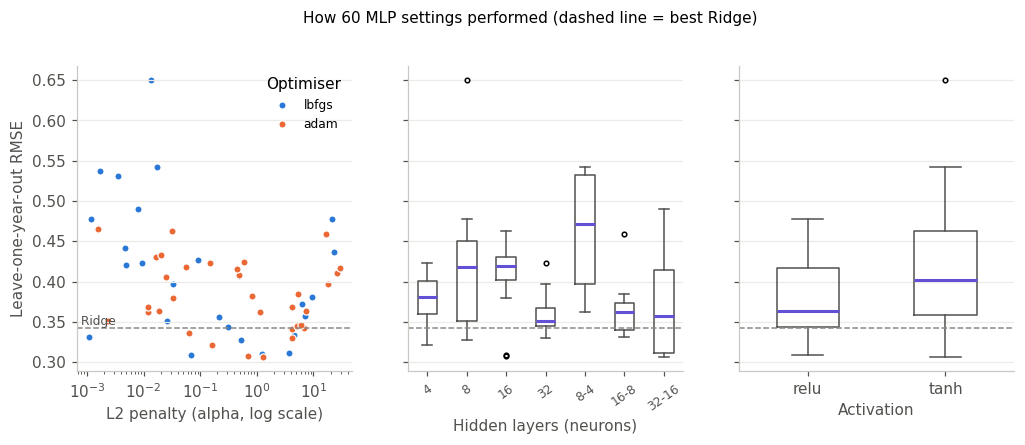

,hyperparameter,effect_on_cv_rmse,measure
0,alpha (L2 penalty),-0.298,Spearman rho
1,learning rate,-0.200,Spearman rho
2,architecture,0.120,range of medians
3,activation,0.039,range of medians
4,optimiser,0.017,range of medians


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
ref = ridge_log["cv_rmse"].min()
for solver, col in [("lbfgs", C["blue"]), ("adam", C["orange"])]:
    d = search_log[search_log["solver"] == solver]
    axes[0].scatter(d["alpha"], d["cv_rmse"], s=22, color=col, label=solver, edgecolor="white", linewidth=0.8)
axes[0].set_xscale("log"); axes[0].set_xlabel("L2 penalty (alpha, log scale)")
axes[0].set_ylabel("Leave-one-year-out RMSE"); axes[0].legend(frameon=False, title="Optimiser", fontsize=8)

archs = ["4", "8", "16", "32", "8-4", "16-8", "32-16"]
vals = [search_log.loc[search_log["architecture"] == a, "cv_rmse"].to_numpy() for a in archs]
axes[1].boxplot(vals, tick_labels=archs, widths=0.5, medianprops={"color": C["violet"], "lw": 2},
                boxprops={"color": C["ink2"]}, whiskerprops={"color": C["ink2"]},
                capprops={"color": C["ink2"]}, flierprops={"markersize": 3})
axes[1].set_xlabel("Hidden layers (neurons)")
axes[1].tick_params(axis="x", labelsize=8, rotation=35)

acts = ["relu", "tanh"]
axes[2].boxplot([search_log.loc[search_log["activation"] == a, "cv_rmse"].to_numpy() for a in acts],
                tick_labels=acts, widths=0.45, medianprops={"color": C["violet"], "lw": 2},
                boxprops={"color": C["ink2"]}, whiskerprops={"color": C["ink2"]},
                capprops={"color": C["ink2"]}, flierprops={"markersize": 3})
axes[2].set_xlabel("Activation")
for ax in axes:
    ax.axhline(ref, color=C["grey"], ls="--", lw=1)
    ax.grid(axis="x", visible=False)
axes[0].text(axes[0].get_xlim()[0], ref, " Ridge", va="bottom", fontsize=8, color=C["ink2"])
fig.suptitle(f"How {N_TRIALS_FULL} MLP settings performed (dashed line = best Ridge)", fontsize=10, y=1.02)
save_fig(fig, "fig4_tuning_study"); plt.show()

# Simple importance of each hyperparameter: rank correlation with CV RMSE / spread across levels
imp = pd.DataFrame({
    "hyperparameter": ["alpha (L2 penalty)", "learning rate", "architecture", "activation", "optimiser"],
    "effect_on_cv_rmse": [
        stats.spearmanr(search_log["alpha"], search_log["cv_rmse"]).statistic,
        stats.spearmanr(search_log["learning_rate_init"], search_log["cv_rmse"]).statistic,
        search_log.groupby("architecture")["cv_rmse"].median().pipe(lambda s: s.max() - s.min()),
        search_log.groupby("activation")["cv_rmse"].median().pipe(lambda s: s.max() - s.min()),
        search_log.groupby("solver")["cv_rmse"].median().pipe(lambda s: s.max() - s.min()),
    ],
    "measure": ["Spearman rho", "Spearman rho", "range of medians", "range of medians", "range of medians"]})
save_table(imp, "table4_hyperparameter_effects")
imp

### 8b. Seed sensitivity: is the network stable?

A neural network starts from random weights, so a different seed can give a different model. Here each model is retrained with 10 different seeds, keeping the hyperparameters chosen in Section 7, and the spread of out-of-sample R² is measured. Ridge has no randomness, so its spread is zero. As a common way to stabilise a network, the table also shows the **average of the 10 MLPs (a seed ensemble)**.

In [17]:
seed_rows, mlp_seed_preds = [], []
for s in SEEDS:
    p, _ = walk_forward(ALL_FEATS, models=["RandomForest", "XGBoost", "MLP"], seed=s, fixed_params=wf_params)
    sc = score(p, ["RandomForest", "XGBoost", "MLP"])
    sc["seed"] = s
    seed_rows.append(sc)
    mlp_seed_preds.append(p["MLP"].to_numpy())
seed_scores = pd.concat(seed_rows, ignore_index=True)

ens = wf_pred[["ticker", "year", "log_pb", "train_mean"]].copy()
ens["MLP seed-ensemble"] = np.mean(mlp_seed_preds, axis=0)
ens_score = score(ens, ["MLP seed-ensemble"])

seed_summary = (seed_scores.groupby("model")["oos_r2"].agg(["mean", "std", "min", "max"])
                .reindex(["RandomForest", "XGBoost", "MLP"]))
r2_ridge = wf_scores.set_index("model").at["Ridge", "oos_r2"]
seed_summary.loc["Ridge"] = [r2_ridge, 0.0, r2_ridge, r2_ridge]
seed_summary.loc["MLP seed-ensemble"] = [ens_score["oos_r2"].iloc[0], np.nan, np.nan, np.nan]
seed_summary = seed_summary.rename(columns=lambda c: f"oos_r2_{c}")
save_table(seed_summary.reset_index(names="model"), "table5_seed_sensitivity")
save_table(seed_scores, "seed_scores_all")
seed_summary

,oos_r2_mean,oos_r2_std,oos_r2_min,oos_r2_max
model,,,,
RandomForest,0.763,0.004,0.756,0.768
XGBoost,0.788,0.011,0.760,0.800
MLP,0.845,0.009,0.829,0.857
Ridge,0.827,0.000,0.827,0.827
MLP seed-ensemble,0.851,NaN,NaN,NaN


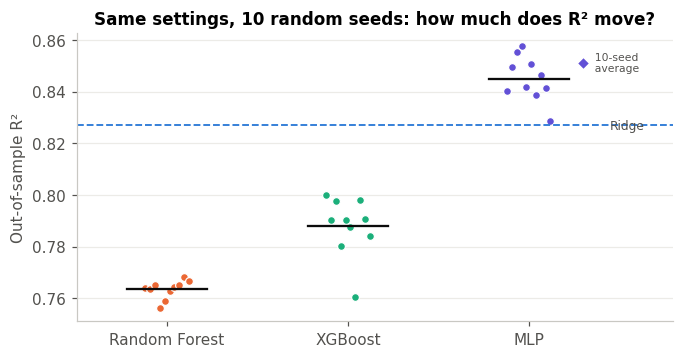

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for k, m in enumerate(["RandomForest", "XGBoost", "MLP"]):
    v = seed_scores.loc[seed_scores["model"] == m, "oos_r2"].to_numpy()
    jitter = np.linspace(-0.12, 0.12, len(v))
    ax.scatter(k + jitter, v, s=26, color=MODEL_COLORS[m], edgecolor="white", linewidth=0.8, zorder=2)
    ax.plot([k - 0.22, k + 0.22], [v.mean()] * 2, color=C["ink"], lw=1.5, zorder=3)
ax.axhline(seed_summary.at["Ridge", "oos_r2_mean"], color=MODEL_COLORS["Ridge"], ls="--", lw=1.2)
ax.text(2.45, seed_summary.at["Ridge", "oos_r2_mean"], "Ridge", va="center", fontsize=8, color=C["ink2"])
ax.scatter(2.3, seed_summary.at["MLP seed-ensemble", "oos_r2_mean"], marker="D", s=34,
           color=C["violet"], edgecolor="white", zorder=3)
ax.text(2.33, seed_summary.at["MLP seed-ensemble", "oos_r2_mean"], "  10-seed\n  average", fontsize=7,
        va="center", color=C["ink2"])
ax.set_xticks(range(3), ["Random Forest", "XGBoost", "MLP"]); ax.set_xlim(-0.5, 2.8)
ax.set_ylabel("Out-of-sample R²"); ax.grid(axis="x", visible=False)
ax.set_title("Same settings, 10 random seeds: how much does R² move?")
save_fig(fig, "fig5_seed_sensitivity"); plt.show()

### 8c. Ablation: which inputs carry the signal?

Each model is re-run three times: with fundamentals only, with market inputs only, and with both. If the fundamentals-only score is close to the combined one, valuations are mostly explained by the company's economics and not by recent price behaviour.

In [19]:
abl_rows = []
for set_name, feats in FEATURE_SETS.items():
    if set_name == "Fundamentals + market":
        sc = wf_scores[wf_scores["model"].isin(["Ridge", "XGBoost", "MLP"])].copy()
    else:
        p, _ = walk_forward(feats, models=["Ridge", "XGBoost", "MLP"], n_trials=N_TRIALS_ABL)
        sc = score(p, ["Ridge", "XGBoost", "MLP"])
    sc["inputs"] = set_name
    abl_rows.append(sc)
ablation = pd.concat(abl_rows).pivot(index="inputs", columns="model", values="oos_r2")[["Ridge", "XGBoost", "MLP"]]
ablation = ablation.reindex(list(FEATURE_SETS))
save_table(ablation.reset_index(), "table6_ablation_oos_r2")
ablation

model,Ridge,XGBoost,MLP
inputs,,,
Fundamentals only,0.767,0.772,0.807
Market only,0.137,-0.118,0.009
Fundamentals + market,0.827,0.785,0.866


### 8d. What is the model paying attention to?

Both final models are fitted on all years with their best full-sample settings.

- **Ridge coefficients** can be read directly: the change in log P/B for a one-standard-deviation change in each input.
- **Permutation importance** works for any model: shuffle one input and measure how much worse the fit gets.
- **Partial dependence** shows how the MLP's fair P/B changes as one input moves, with everything else held at its observed values.

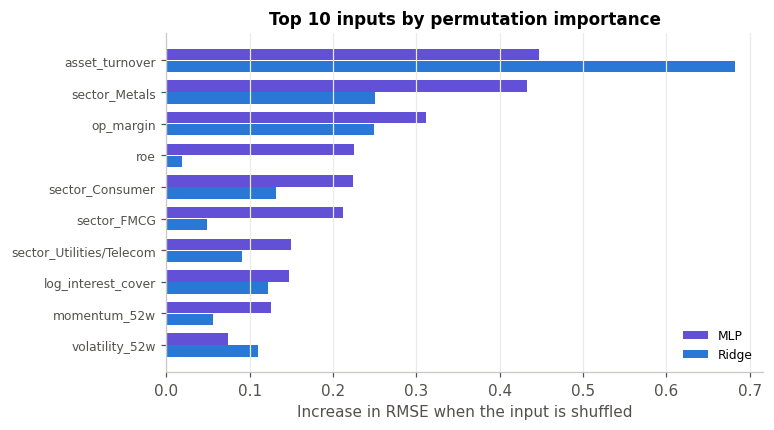

,ridge_coef_per_sd,ridge_perm_importance,mlp_perm_importance
asset_turnover,0.656,6.820e-01,0.447
sector_Metals,-0.321,2.497e-01,0.433
op_margin,0.316,2.489e-01,0.311
roe,0.072,1.839e-02,0.225
sector_Consumer,0.214,1.316e-01,0.224
sector_FMCG,0.124,4.902e-02,0.212
sector_Utilities/Telecom,-0.177,9.095e-02,0.149
log_interest_cover,-0.210,1.217e-01,0.147
momentum_52w,0.129,5.594e-02,0.125
volatility_52w,-0.188,1.103e-01,0.074


In [20]:
final_mlp = build("MLP", best_full).fit(data[ALL_FEATS], data["log_pb"])
final_ridge = build("Ridge", ridge_full).fit(data[ALL_FEATS], data["log_pb"])

coef = pd.Series(final_ridge[-1].coef_, index=ALL_FEATS)
pi = permutation_importance(final_mlp, data[ALL_FEATS], data["log_pb"], n_repeats=30,
                            random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=1)
pi_r = permutation_importance(final_ridge, data[ALL_FEATS], data["log_pb"], n_repeats=30,
                              random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=1)
interp = pd.DataFrame({"ridge_coef_per_sd": coef,
                       "ridge_perm_importance": pi_r.importances_mean,
                       "mlp_perm_importance": pi.importances_mean}).sort_values("mlp_perm_importance", ascending=False)
save_table(interp.reset_index(names="feature"), "table7_interpretability")

top = interp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(top))
ax.barh(y + 0.19, top["mlp_perm_importance"], height=0.36, color=C["violet"], label="MLP")
ax.barh(y - 0.19, top["ridge_perm_importance"], height=0.36, color=C["blue"], label="Ridge")
ax.set_yticks(y, top.index, fontsize=8)
ax.set_xlabel("Increase in RMSE when the input is shuffled")
ax.set_title("Top 10 inputs by permutation importance")
ax.legend(frameon=False, fontsize=8); ax.grid(axis="y", visible=False)
save_fig(fig, "fig6_importance"); plt.show()
interp

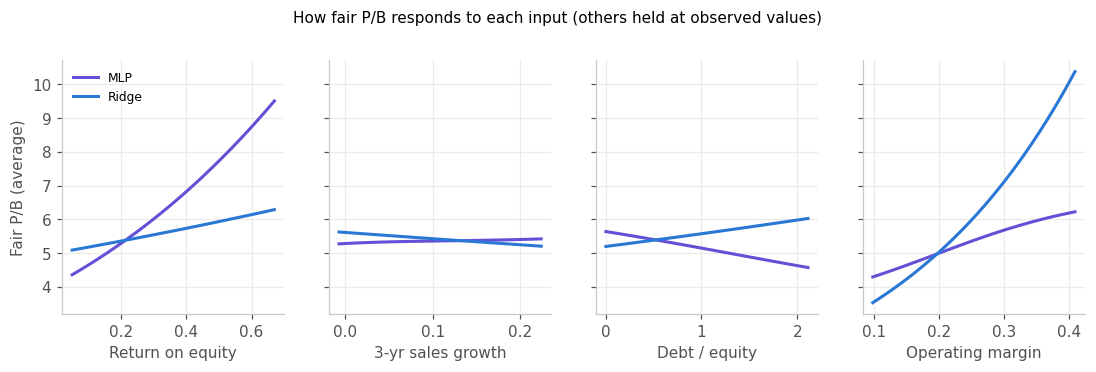

In [21]:
pd_feats = ["roe", "sales_cagr_3y", "debt_equity", "op_margin"]
labels = {"roe": "Return on equity", "sales_cagr_3y": "3-yr sales growth",
          "debt_equity": "Debt / equity", "op_margin": "Operating margin"}
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, f in zip(axes, pd_feats):
    for model, col in [(final_mlp, C["violet"]), (final_ridge, C["blue"])]:
        r = partial_dependence(model, data[ALL_FEATS], [f], grid_resolution=30,
                               percentiles=(0.05, 0.95), kind="average")
        ax.plot(r["grid_values"][0], np.exp(r["average"][0]), color=col, lw=2)
    ax.set_xlabel(labels[f])
axes[0].set_ylabel("Fair P/B (average)")
axes[0].legend(["MLP", "Ridge"], frameon=False, fontsize=8)
fig.suptitle("How fair P/B responds to each input (others held at observed values)", fontsize=10, y=1.03)
save_fig(fig, "fig7_partial_dependence"); plt.show()

## 9. Investment test: does mispricing predict next year's return?

Each 30 June from 2022 to 2025, a stock's **mispricing** is its actual log P/B minus the model's out-of-sample fair value. A negative value means it looks cheap for its fundamentals. For each year the test reports:

- the **rank correlation (IC)** between cheapness and the next 52-week total return;
- the average return of the **5 cheapest** and the **5 most expensive** stocks, against the equal-weighted average of all 20 and the NIFTY 50.

With 20 stocks and 4 years this is a pilot. The numbers show the direction of the effect, not statistical proof.

In [22]:
bt_rows = []
for model in ["Ridge", "MLP"]:
    for yr in BACKTEST_YEARS:
        d = wf_pred[(wf_pred["year"] == yr)].dropna(subset=["fwd_return_52w"]).copy()
        d["cheapness"] = -(d["log_pb"] - d[model])
        d = d.sort_values("cheapness", ascending=False, kind="stable")
        bt_rows.append({"model": model, "year": yr, "n": len(d),
                        "ic": stats.spearmanr(d["cheapness"], d["fwd_return_52w"]).statistic,
                        "cheapest5": d["fwd_return_52w"].head(5).mean(),
                        "expensive5": d["fwd_return_52w"].tail(5).mean(),
                        "equal_weight_all": d["fwd_return_52w"].mean(),
                        "nifty50": d["nifty_fwd_52w"].iloc[0]})
backtest = pd.DataFrame(bt_rows)
backtest["cheap_minus_expensive"] = backtest["cheapest5"] - backtest["expensive5"]
summary = backtest.groupby("model")[["ic", "cheapest5", "expensive5", "cheap_minus_expensive",
                                      "equal_weight_all", "nifty50"]].mean()
summary["ic_t_stat"] = backtest.groupby("model")["ic"].apply(lambda s: s.mean() / (s.std(ddof=1) / np.sqrt(len(s))))
save_table(backtest, "table8_backtest_by_year")
save_table(summary.reset_index(), "table9_backtest_summary")
display(backtest.round(3))
summary.round(3)

,model,year,n,ic,cheapest5,expensive5,equal_weight_all,nifty50,cheap_minus_expensive
0,Ridge,2022,20,0.364,0.325,0.131,0.282,0.218,0.194
1,Ridge,2023,20,-0.015,0.424,0.433,0.405,0.251,-0.009
2,Ridge,2024,20,-0.173,0.009,0.090,0.038,0.068,-0.081
3,Ridge,2025,20,-0.189,-0.073,0.009,0.004,-0.047,-0.082
4,MLP,2022,20,0.171,0.330,0.131,0.282,0.218,0.199
5,MLP,2023,20,-0.314,0.130,0.457,0.405,0.251,-0.327
6,MLP,2024,20,-0.209,0.009,0.097,0.038,0.068,-0.088
7,MLP,2025,20,-0.284,-0.073,0.056,0.004,-0.047,-0.129


,ic,cheapest5,expensive5,cheap_minus_expensive,equal_weight_all,nifty50,ic_t_stat
model,,,,,,,
MLP,-0.159,0.099,0.185,-0.086,0.182,0.123,-1.415
Ridge,-0.003,0.171,0.166,0.005,0.182,0.123,-0.026


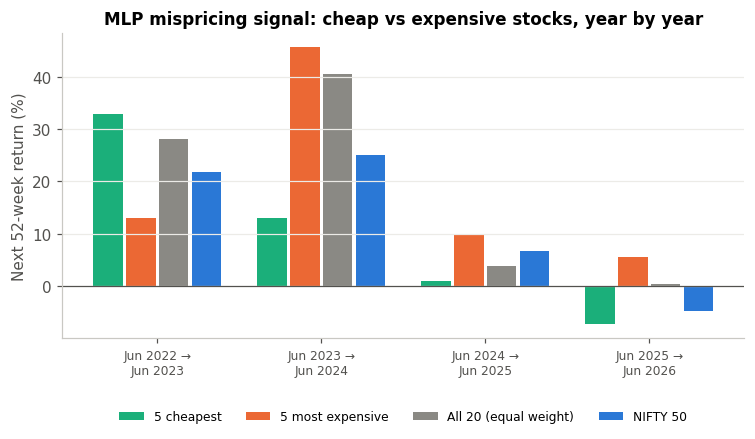

In [23]:
d = backtest[backtest["model"] == "MLP"].set_index("year")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(d)); w = 0.2
for k, (c, lab, col) in enumerate([("cheapest5", "5 cheapest", C["aqua"]),
                                    ("expensive5", "5 most expensive", C["orange"]),
                                    ("equal_weight_all", "All 20 (equal weight)", C["grey"]),
                                    ("nifty50", "NIFTY 50", C["blue"])]):
    ax.bar(x + (k - 1.5) * w, d[c] * 100, width=w - 0.02, color=col, label=lab)
ax.axhline(0, color=C["ink2"], lw=0.8)
ax.set_xticks(x, [f"Jun {y} →\nJun {y+1}" for y in d.index], fontsize=8)
ax.set_ylabel("Next 52-week return (%)")
ax.set_title("MLP mispricing signal: cheap vs expensive stocks, year by year")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.grid(axis="x", visible=False)
save_fig(fig, "fig8_backtest"); plt.show()

## 10. Business use: a fair P/B for an unlisted company

The same model can value a private company from its fundamentals, which is how private businesses are usually valued against listed peers. Market inputs don't exist for an unlisted firm, so they're set to the universe median. The example below is **illustrative**: replace the numbers with a real company's figures.

Because the model was trained only on 20 large caps, any estimate for a small private firm needs a further discount for size and illiquidity, which this model doesn't capture.

In [24]:
def fair_value(sector, book_value_cr, **fundamentals):
    row = {f: np.nan for f in ALL_FEATS}
    row.update({m: data[m].median() for m in MKT_FEATS})
    clipped = []
    for k, v in fundamentals.items():
        lo, hi = data[k].min(), data[k].max()
        if not lo <= v <= hi:
            clipped.append(k)
        row[k] = float(np.clip(v, lo, hi))   # the model cannot extrapolate beyond companies it has seen
    if clipped:
        print("Inputs outside the training range, set to the nearest observed value:", clipped)
    for s in SECTORS:
        row[f"sector_{s}"] = float(s == sector)
    X = pd.DataFrame([row])[ALL_FEATS]
    out = {}
    for name, model in [("Ridge", final_ridge), ("MLP", final_mlp)]:
        pb = float(np.exp(model.predict(X)[0]))
        out[name] = {"fair_P/B": round(pb, 2), "implied_equity_value_cr": round(pb * book_value_cr, 1)}
    return pd.DataFrame(out).T

example = fair_value("FMCG", book_value_cr=3000, roe=0.18, op_margin=0.10, sales_cagr_3y=0.12,
                     debt_equity=0.4, log_interest_cover=np.log1p(8), asset_turnover=1.8,
                     payout=0.3, cash_conversion=0.9, roe_volatility_3y=0.03, log_sales=np.log(15000))
example

,fair_P/B,implied_equity_value_cr
Ridge,28.33,84994.1
MLP,25.46,76366.3


## 11. Reproducibility fingerprint

The key result tables are hashed into one fingerprint. If the notebook is rerun on the same frozen data and library versions, the fingerprint must match, and the cell below says whether it does. Library versions are saved in `outputs/environment.json`.

In [25]:
key_tables = {"walkforward": wf_scores, "rmse_by_year": by_year.reset_index(), "search": search_log.drop(columns="hidden_layer_sizes"),
              "seeds": seed_summary.reset_index(), "ablation": ablation.reset_index(),
              "interp": interp.reset_index(), "backtest": backtest}
h = hashlib.sha256()
for k in sorted(key_tables):
    h.update(k.encode()); h.update(key_tables[k].round(10).to_csv(index=False).encode())
fingerprint = h.hexdigest()

fp_file = OUT / "fingerprint.txt"
previous = fp_file.read_text().strip() if fp_file.exists() else None
fp_file.write_text(fingerprint)
print("Results fingerprint:", fingerprint)
if previous is None:
    print("First run: fingerprint saved. Rerun the notebook to confirm it reproduces.")
elif previous == fingerprint:
    print("IDENTICAL to previous run.")
else:
    print("DIFFERENT from previous run:", previous, "\nCheck data checksums and outputs/environment.json.")

Results fingerprint: cd8ace47ea2c94a683cbb3dafad89d5c3044820139dfd8217bb86526b194aa5d
First run: fingerprint saved. Rerun the notebook to confirm it reproduces.


## Outputs written

- `outputs/tables/`: every table above as CSV (`table1` … `table9`, plus the modelling table, predictions and search log)
- `outputs/figures/`: figures `fig1` … `fig8` as PNG
- `outputs/environment.json`: the exact library versions used
- `outputs/fingerprint.txt`: the results fingerprint

**Moving to the full Prowess dataset:** replace the reader in Section 3 with one for the Prowess export, keeping the same column names: `sales`, `net_profit`, `reserves` and so on. Everything after Section 3 runs unchanged.